# Étape 2 — Pré-traitement, split & baseline propre


## 0. Imports et setup

On utilise notre module `src/dc_utils/` pour ne pas réécrire la métrique partout. C'est aussi ce qui rend le projet *reproductible* pour le rapport.

In [1]:
import sys, os, time, random
from pathlib import Path

# Permet d'importer dc_utils depuis src/
sys.path.insert(0, str(Path.cwd() / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from PIL import Image
from tqdm.auto import tqdm

from dc_utils.paths   import TRAIN_CSV, TEST_CSV, IMAGE_DIR, DATA_DIR, ARTIFACTS_DIR
from dc_utils.io      import load_train, load_test
from dc_utils.splits  import stratified_split
from dc_utils.metric  import compute_score, torch_weighted_mse, weighted_error

ARTIFACTS_DIR.mkdir(exist_ok=True)

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device :', device, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

<repo>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device : cuda | NVIDIA GeForce RTX 3090


## 1. Pré-traitement 

On enrichit les CSV avec `db`, `identity`, `occ_bin`, et on filtre les lignes pointant vers des fichiers manquants (i.e. tout `database2`).

In [3]:
df_train_full = load_train(TRAIN_CSV)
df_test_full  = load_test(TEST_CSV)

missing_dbs = {'database2'}
df_train_clean = df_train_full[~df_train_full['db'].isin(missing_dbs)].reset_index(drop=True)
df_test_clean  = df_test_full.copy()  # on garde tout le test, on imputera plus tard
df_test_clean['needs_imputation'] = df_test_clean['db'].isin(missing_dbs)

print(f'Train brut : {len(df_train_full):,}  -> Train clean : {len(df_train_clean):,} '
      f'(perdu : {len(df_train_full)-len(df_train_clean):,})')
print(f'Test brut  : {len(df_test_full):,}  -> Test  clean : {len(df_test_clean):,} '
      f'(à imputer : {df_test_clean["needs_imputation"].sum():,})')

df_train_clean.to_csv(DATA_DIR / 'train_clean.csv', index=False)
df_test_clean.to_csv(DATA_DIR / 'test_clean.csv', index=False)
df_train_clean.head()

Train brut : 100,000  -> Train clean : 99,770 (perdu : 230)
Test brut  : 29,980  -> Test  clean : 29,980 (à imputer : 118)


,filename,FaceOcclusion,gender,db,identity,occ_bin
0,database3/database3/m.01w0zk1/66-FaceId-0_alig...,0.024005,1.0,database3,db3:m.01w0zk1,0-5
1,database3/database3/m.016ywr/88-FaceId-0_align...,0.030028,1.0,database3,db3:m.016ywr,0-5
2,database3/database3/m.02dfmb/105-FaceId-0_alig...,0.009984,0.0,database3,db3:m.02dfmb,0-5
3,database3/database3/m.01_h_s/33-FaceId-5_align...,0.255016,1.0,database3,db3:m.01_h_s,20-30
4,database3/database3/m.02lqkv/85-FaceId-0_align...,0.252091,1.0,database3,db3:m.02lqkv,20-30


## 2. Split stratifié train / validation

In [4]:
df_tr, df_val = stratified_split(df_train_clean, val_size=0.10, seed=SEED)
print(f'Train : {len(df_tr):,}  |  Val : {len(df_val):,}')

df_tr.to_csv(DATA_DIR / 'train_split.csv', index=False)
df_val.to_csv(DATA_DIR / 'val_split.csv', index=False)

# Vérifications
print('\n--- Proportions de genre ---')
for name, d in [('train', df_tr), ('val', df_val)]:
    p = d['gender'].value_counts(normalize=True).round(4).to_dict()
    print(f'{name}: F={p.get(0.0,0):.4f}  M={p.get(1.0,0):.4f}')

print('\n--- Effectifs val par bucket × genre ---')
ct = pd.crosstab(df_val['occ_bin'], df_val['gender'].map({0.0:'F',1.0:'M'}))
print(ct)

Train : 89,793  |  Val : 9,977

--- Proportions de genre ---
train: F=0.3236  M=0.6764
val: F=0.3236  M=0.6764

--- Effectifs val par bucket × genre ---
gender      F     M
occ_bin            
0-5       722  4287
5-10      763  1110
10-20    1067   883
20-30     464   369
30-50     212    97
50-70       1     2


## 3. Sanity check 

In [5]:
y_val = df_val['FaceOcclusion'].values
g_val = df_val['gender'].values

def score_constant(value):
    df = pd.DataFrame({'pred': np.full_like(y_val, value, dtype=float),
                       'target': y_val, 'gender': g_val})
    return compute_score(df)

def score_per_gender(mean_F, mean_M):
    pred = np.where(g_val == 0.0, mean_F, mean_M)
    df = pd.DataFrame({'pred': pred, 'target': y_val, 'gender': g_val})
    return compute_score(df)

mean_global = df_tr['FaceOcclusion'].mean()
mean_F = df_tr.loc[df_tr['gender']==0.0, 'FaceOcclusion'].mean()
mean_M = df_tr.loc[df_tr['gender']==1.0, 'FaceOcclusion'].mean()
print(f'Train mean global = {mean_global:.4f}  | mean F = {mean_F:.4f}  | mean M = {mean_M:.4f}')
print()
print('=== Baselines triviales sur la val ===')
print('pred=0          :', score_constant(0.0))
print('pred=mean_global:', score_constant(mean_global))
print('pred=mean/genre :', score_per_gender(mean_F, mean_M))

Train mean global = 0.0827  | mean F = 0.1284  | mean M = 0.0607

=== Baselines triviales sur la val ===
pred=0          : {'score': 0.052878912967434445, 'err_F': 0.0431458148599544, 'err_M': 0.023679618644994307, 'gap': 0.01946619621496009, 'n_F': 3229, 'n_M': 6748}
pred=mean_global: {'score': 0.0242361024155992, 'err_F': 0.019897016144919975, 'err_M': 0.011218843603561526, 'gap': 0.008678172541358449, 'n_F': 3229, 'n_M': 6748}
pred=mean/genre : {'score': 0.013337807070032728, 'err_F': 0.012897625554628133, 'err_M': 0.013191079898231196, 'gap': 0.00029345434360306295, 'n_F': 3229, 'n_M': 6748}


## 4. Dataset & DataLoaders

Améliorations vs baseline d'exemple :
- **Normalisation ImageNet** (cohérent avec `mobilenet_v3_small` pré-entraîné).
- **Augmentation horizontale uniquement** pour la baseline 
- Pas d'augmentation sur la validation.

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

tf_train = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
tf_eval = T.Compose([
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class OcclusionDataset(torch.utils.data.Dataset):
    def __init__(self, df, image_dir, transform, has_target=True):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.has_target = has_target
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(self.image_dir / row['filename']).convert('RGB')
        x = self.transform(img)
        if self.has_target:
            y = np.float32(row['FaceOcclusion'])
            g = np.float32(row['gender'])
            return x, y, g, row['filename']
        return x, row['filename']

ds_train = OcclusionDataset(df_tr,  IMAGE_DIR, tf_train, has_target=True)
ds_val   = OcclusionDataset(df_val, IMAGE_DIR, tf_eval,  has_target=True)

BS = 128
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=BS, shuffle=True,  num_workers=4, pin_memory=True, drop_last=True)
dl_val   = torch.utils.data.DataLoader(ds_val,   batch_size=BS, shuffle=False, num_workers=4, pin_memory=True)
print(f'Batches train: {len(dl_train)}  | Batches val: {len(dl_val)}')

Batches train: 701  | Batches val: 78


## 5. Modèle : mobilenet_v3_small pré-entraîné + tête sigmoid

In [7]:
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

class OcclusionRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        in_features = backbone.classifier[-1].in_features
        backbone.classifier[-1] = nn.Linear(in_features, 1)
        self.backbone = backbone
    def forward(self, x):
        # logits puis sigmoid -> [0, 1]
        return torch.sigmoid(self.backbone(x)).squeeze(-1)

model = OcclusionRegressor().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Modèle: mobilenet_v3_small + sigmoid | params trainables: {n_params:,}')

Modèle: mobilenet_v3_small + sigmoid | params trainables: 1,518,881


## 6. Train

In [10]:
@torch.inference_mode()
def evaluate(model, dl):
    model.eval()
    rows = []
    for X, y, g, fn in dl:
        X = X.to(device, non_blocking=True)
        with torch.amp.autocast('cuda'):
            p = model(X).float().cpu().numpy()
        rows.extend({'pred': float(p[i]), 'target': float(y[i]), 'gender': float(g[i])} for i in range(len(p)))
    df = pd.DataFrame(rows)
    return compute_score(df), df

def train_one_epoch(model, dl, optim, scaler):
    model.train()
    losses = []
    pbar = tqdm(dl, desc='train', leave=False)
    for X, y, g, fn in pbar:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        optim.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            pred = model(X)
            loss = torch_weighted_mse(pred, y)
        scaler.scale(loss).backward()
        scaler.step(optim)
        scaler.update()
        losses.append(loss.item())
        pbar.set_postfix(loss=f'{loss.item():.5f}')
    return float(np.mean(losses))

EPOCHS = 8
LR = 1e-3
optim_  = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched   = torch.optim.lr_scheduler.CosineAnnealingLR(optim_, T_max=EPOCHS)
scaler  = torch.cuda.amp.GradScaler()

best_score = float('inf')
history = []
for epoch in range(1, EPOCHS+1):
    t0 = time.time()
    train_loss = train_one_epoch(model, dl_train, optim_, scaler)
    val_metrics, _ = evaluate(model, dl_val)
    sched.step()
    dt = time.time() - t0
    history.append({'epoch': epoch, 'train_loss': train_loss, **val_metrics, 'sec': dt})
    print(f'epoch {epoch:2d} | loss {train_loss:.5f} | '
          f'score {val_metrics["score"]:.5f} | err_F {val_metrics["err_F"]:.5f} | '
          f'err_M {val_metrics["err_M"]:.5f} | gap {val_metrics["gap"]:.5f} | {dt:.0f}s')
    if val_metrics['score'] < best_score:
        best_score = val_metrics['score']
        torch.save({'model': model.state_dict(), 'epoch': epoch, 'val': val_metrics},
                   ARTIFACTS_DIR / 'baseline_mbv3s.pt')
        print(f'  -> saved (best {best_score:.5f})')

pd.DataFrame(history)

epoch  1 | loss 0.00292 | score 0.00774 | err_F 0.00709 | err_M 0.00580 | gap 0.00130 | 185s
  -> saved (best 0.00774)


epoch  2 | loss 0.00156 | score 0.00165 | err_F 0.00089 | err_M 0.00139 | gap 0.00051 | 140s
  -> saved (best 0.00165)


epoch  3 | loss 0.00127 | score 0.00186 | err_F 0.00109 | err_M 0.00160 | gap 0.00051 | 137s


epoch  4 | loss 0.00113 | score 0.00153 | err_F 0.00076 | err_M 0.00127 | gap 0.00051 | 147s
  -> saved (best 0.00153)


epoch  5 | loss 0.00087 | score 0.00148 | err_F 0.00071 | err_M 0.00123 | gap 0.00051 | 152s
  -> saved (best 0.00148)


epoch  6 | loss 0.00071 | score 0.00136 | err_F 0.00072 | err_M 0.00114 | gap 0.00043 | 139s
  -> saved (best 0.00136)


epoch  7 | loss 0.00058 | score 0.00126 | err_F 0.00063 | err_M 0.00105 | gap 0.00043 | 140s
  -> saved (best 0.00126)


epoch  8 | loss 0.00051 | score 0.00125 | err_F 0.00061 | err_M 0.00104 | gap 0.00043 | 143s
  -> saved (best 0.00125)


,epoch,train_loss,score,err_F,err_M,gap,n_F,n_M,sec
0,1,0.002923,0.007740,0.007092,0.005795,0.001297,3229,6748,185.261170
1,2,0.001563,0.001648,0.000887,0.001394,0.000507,3229,6748,140.135822
2,3,0.001273,0.001858,0.001093,0.001603,0.000510,3229,6748,136.736613
3,4,0.001133,0.001526,0.000762,0.001271,0.000509,3229,6748,147.216800
4,5,0.000867,0.001484,0.000713,0.001227,0.000514,3229,6748,151.510604
5,6,0.000707,0.001359,0.000717,0.001145,0.000427,3229,6748,138.740807
6,7,0.000585,0.001264,0.000627,0.001052,0.000425,3229,6748,139.554101
7,8,0.000512,0.001253,0.000608,0.001038,0.000430,3229,6748,142.863126


## 7. Analyse du meilleur modèle

In [11]:
ckpt = torch.load(ARTIFACTS_DIR / 'baseline_mbv3s.pt', map_location=device, weights_only=False)
model.load_state_dict(ckpt['model'])
val_metrics, df_val_pred = evaluate(model, dl_val)
print('Best val metrics :', val_metrics)
df_val_pred['err'] = (df_val_pred['pred'] - df_val_pred['target'])**2 * (1/30 + df_val_pred['target'])

# Erreur par bucket 
df_val_pred['occ_bin'] = pd.cut(df_val_pred['target'],
                                bins=[0,0.05,0.10,0.20,0.30,0.50,0.70,1.01],
                                labels=['0-5','5-10','10-20','20-30','30-50','50-70','70-100'],
                                include_lowest=True)
print('\nErreur par bucket (somme contribuant au score):')
print(df_val_pred.groupby('occ_bin', observed=True)['err'].agg(['count','sum','mean']))

Best val metrics : {'score': 0.0012531371022129634, 'err_F': 0.0006081912760809864, 'err_M': 0.0010381551601689712, 'gap': 0.0004299638840879848, 'n_F': 3229, 'n_M': 6748}

Erreur par bucket (somme contribuant au score):
         count       sum      mean
occ_bin                           
0-5       5009  0.128244  0.000026
5-10      1873  0.114388  0.000061
10-20     1950  0.263459  0.000135
20-30      833  0.214790  0.000258
30-50      309  0.183596  0.000594
50-70        3  0.068134  0.022711


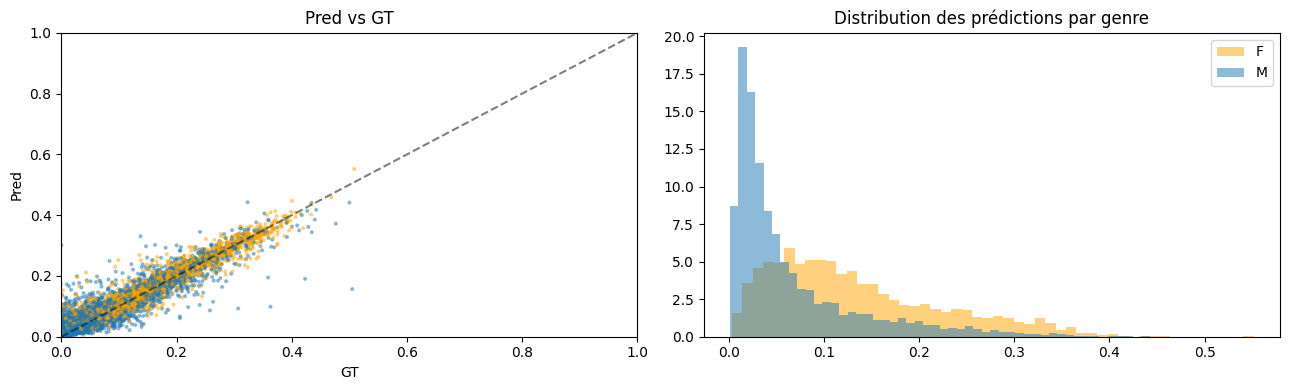

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(df_val_pred['target'], df_val_pred['pred'],
                c=df_val_pred['gender'].map({0.0:'orange',1.0:'tab:blue'}), s=4, alpha=0.4)
axes[0].plot([0,1],[0,1],'k--', alpha=0.5)
axes[0].set_xlabel('GT'); axes[0].set_ylabel('Pred'); axes[0].set_title('Pred vs GT')
axes[0].set_xlim(0,1); axes[0].set_ylim(0,1)

for g, c in [(0.0,'orange'),(1.0,'tab:blue')]:
    sub = df_val_pred[df_val_pred['gender']==g]
    axes[1].hist(sub['pred'], bins=50, alpha=0.5, density=True, label=f'{"F" if g==0 else "M"}', color=c)
axes[1].set_title('Distribution des prédictions par genre')
axes[1].legend(); plt.tight_layout(); plt.show()